# CivicFlux — Water-Network Fault Detection

## 01. Problem definition

Use the public BattLeDIM/L-TOWN benchmark to detect whether **a new leakage episode began within the preceding 24 hours**, at hourly observation instants. This is early-stage network-level detection, not localization or a classifier of every ongoing leak. A negative label may include an older persistent leak. The endpoint is chosen to avoid interpreting the near-continuous existence of background leakage as a meaningful easy classification task.

L-TOWN is a hypothetical benchmark generated from a Cyprus network. Its readings and leakage labels are simulated benchmark evidence, never real Delhi incidents. This retrospective study uses released ground-truth leak-flow tables; it is not a competition submission or a claim of reproducing official BattLeDIM scoring.

### Environment and versioned outputs

Reuse the existing project, source checksum utility and shared graph representation. No legacy notebook is regenerated.

In [1]:
from pathlib import Path
import sys,json,platform,importlib.metadata,time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import joblib
ROOT=Path.cwd() if (Path.cwd()/'civicflux_core.py').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from civicflux_core import sha256
from src.civicflux.research import pipeline,binary_metrics,choose_threshold,write_json
from sklearn.model_selection import cross_validate,RandomizedSearchCV,TimeSeriesSplit,GroupKFold
from sklearn.linear_model import LogisticRegression,Ridge
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor
from sklearn.dummy import DummyClassifier,DummyRegressor
from sklearn.metrics import ConfusionMatrixDisplay,PrecisionRecallDisplay,classification_report,mean_absolute_error,mean_squared_error
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from sklearn.base import clone
import networkx as nx
sns.set_theme(style='whitegrid',palette='colorblind')
plt.rcParams.update({'figure.figsize':(11,4),'figure.dpi':110})
SEED=42

from src.civicflux.water import *
from src.civicflux.graph import read_epanet
OUT=ROOT/'artifacts/water_network/v1.1.0'
OUT.mkdir(parents=True,exist_ok=True)
DATA=ROOT/'data/raw/battledim'
from src.civicflux.review import select_score_threshold as choose_threshold

## 02. Source verification and measurement contract

Official [Zenodo record 4017659](https://zenodo.org/records/4017659) and [BattLeDIM organizers](https://battledim.ucy.ac.cy/) provide the public benchmark. License: CC BY 4.0; credit Vrachimis and coauthors, DOI 10.5281/zenodo.4017659. Download with `python download_battledim.py`; no account/API key was required. The script checks every selected file against official MD5 metadata.

CSV format uses semicolon separators and decimal commas, timestamps `YYYY-MM-DD HH:MM:SS`, at five-minute cadence. Timezone/receipt latency are unspecified and remain source-local. Pressures and tank level are meters; flows/leak outflows are m³/hour; optional AMR demands are L/hour. The nominal EPANET graph contains sensor node/link identities, relative coordinates and nominal demands. Those coordinates are not Delhi GIS locations. Demand EDA uses nominal network demand and patterns, not invented measured AMR data.

### Verify files, checksums and licensing

The source metadata snapshot and file contents establish the version used. Missing required files stop the study.

In [2]:
import hashlib
record=json.loads((DATA/'record.json').read_text())
print('License',record['metadata']['license'])
required=['L-TOWN.inp','README.txt','dataset_configuration.yaml']+[f'{y}_{kind}.csv' for y in [2018,2019] for kind in ['SCADA_Pressures','SCADA_Flows','SCADA_Levels','Leakages']]
verified=[]
for name in required:
    path=DATA/name;entry=next(e for e in record['files'] if e['key']==name)
    assert path.exists(),f'Run download_battledim.py: missing {name}'
    assert hashlib.md5(path.read_bytes()).hexdigest()==entry['checksum'].split(':')[1]
    verified.append({'file':name,'bytes':path.stat().st_size,'sha256':sha256(path)})
display(pd.DataFrame(verified));write_json(OUT/'source_manifest.json',verified)

License {'id': 'cc-by-4.0'}


,file,bytes,sha256
0,L-TOWN.inp,412200,a7551b86745f4cc3433c78e60023077fa1386947d4d353...
1,README.txt,5303,e6a3e83bdf7f116c47c72640de6e4785fd3437b9642844...
2,dataset_configuration.yaml,3926,23471d8989d82c66a4909816ea248f7588d8ccc910e142...
3,2018_SCADA_Pressures.csv,22593812,7782d890a7195699be94ddc01cba392da7ca285908afff...
4,2018_SCADA_Flows.csv,4023420,7f7e8625c9d92b083ee079a54cffb9ef803876de1e3501...
5,2018_SCADA_Levels.csv,2721000,a1fc5f0229448a620b6220f4d079b3162a255b3070acdc...
6,2018_Leakages.csv,6234468,e1abd9d549a18880d8ae704dc90c06c8a3d5aecbd2541f...
7,2019_SCADA_Pressures.csv,22606417,a4af6616059cc9b366bbab76d880b2c772df544970c6ff...
8,2019_SCADA_Flows.csv,4130511,c709ea5ecc03197e1fe70cf4c2de7225f71015acb50a74...
9,2019_SCADA_Levels.csv,2720780,00624e97b72e63233beeccb48db528d43e59a87b116d02...


### Load SCADA and independent label tables

Pressure/flow/level observations are joined only on exact timestamps inside this one documented network.

In [3]:
measurements,leakages=load_benchmark(DATA)
graph=read_epanet(DATA/'L-TOWN.inp')
for name,d in measurements.items():
    print(name,d.shape,d.index.min(),d.index.max());display(d.head(3))
print('Leakage label matrix',leakages.shape,'Topology',graph.number_of_nodes(),'nodes',graph.number_of_edges(),'links')

Pressures (210240, 33) 2018-01-01 00:00:00 2019-12-31 23:55:00


,n1,n4,n31,n54,n105,n114,n163,n188,n215,n229,...,n549,n613,n636,n644,n679,n722,n726,n740,n752,n769
Timestamp,,,,,,,,,,,,,,,,,,,,,
2018-01-01 00:00:00,28.92,33.87,37.13,37.13,50.52,53.99,52.56,55.32,39.09,52.53,...,54.80,56.16,45.53,47.62,47.33,46.14,47.12,43.81,49.17,48.50
2018-01-01 00:05:00,28.94,33.89,37.16,37.23,50.60,54.09,52.67,55.42,39.10,52.67,...,54.90,56.26,45.61,47.71,47.39,46.19,47.17,43.83,49.22,48.54
2018-01-01 00:10:00,28.96,33.91,37.18,37.21,50.57,54.05,52.64,55.39,39.09,52.64,...,54.87,56.24,45.61,47.71,47.41,46.20,47.19,43.84,49.24,48.56


Flows (210240, 3) 2018-01-01 00:00:00 2019-12-31 23:55:00


,p227,p235,PUMP_1
Timestamp,,,
2018-01-01 00:00:00,77.77,83.93,44.04
2018-01-01 00:05:00,72.51,76.34,44.06
2018-01-01 00:10:00,71.54,78.68,44.06


Levels (210240, 1) 2018-01-01 00:00:00 2019-12-31 23:55:00


,T1
Timestamp,
2018-01-01 00:00:00,3.50
2018-01-01 00:05:00,3.51
2018-01-01 00:10:00,3.53


Leakage label matrix (210240, 33) Topology 785 nodes 909 links


## 03. Data inspection and sensor mapping

Inspect every measurement family for missingness, duplicates, cadence, units and supported IDs. Flow sensors identify links; pressure sensors identify nodes. Link orientation is not inferred from count values. Topology is nominal and may differ from the hydraulic simulator used to generate readings.

### Coverage and missingness

Missing readings are not imputed labels. Current predictor gaps are handled in the train-fitted preprocessing and explicitly guarded at serving.

,count,mean,std,min,25%,50%,75%,max
n1,210240.0,28.102923,0.547333,25.67,27.69,28.07,28.53,29.36
n4,210240.0,33.206609,0.537429,30.71,32.80,33.18,33.64,34.31
n31,210240.0,36.558598,0.505036,34.59,36.16,36.54,36.97,37.57
n54,210240.0,36.408426,0.963687,33.58,35.74,36.46,37.16,38.29
n105,210240.0,50.112915,0.421547,48.77,49.80,50.12,50.43,50.95
n114,210240.0,53.511495,0.491822,51.96,53.15,53.52,53.89,54.49
n163,210240.0,51.840827,0.780841,49.38,51.31,51.89,52.43,53.35
n188,210240.0,54.597371,0.766767,52.14,54.07,54.65,55.17,56.08


,count,mean,std,min,25%,50%,75%,max
p227,210240.0,112.440700,35.850462,15.93,89.86,114.285,136.13,205.44
p235,210240.0,113.820067,33.838176,17.17,91.73,117.540,139.09,195.28
PUMP_1,210240.0,30.484383,20.217631,0.00,0.00,43.800,43.99,44.40


,count,mean,std,min,25%,50%,75%,max
T1,210240.0,3.113824,0.458739,1.95,2.72,3.11,3.51,3.9


,family,rows,sensors,missing,duplicate_times,cadence_minutes
0,Pressures,210240,33,0,0,5.0
1,Flows,210240,3,0,0,5.0
2,Levels,210240,1,0,0,5.0


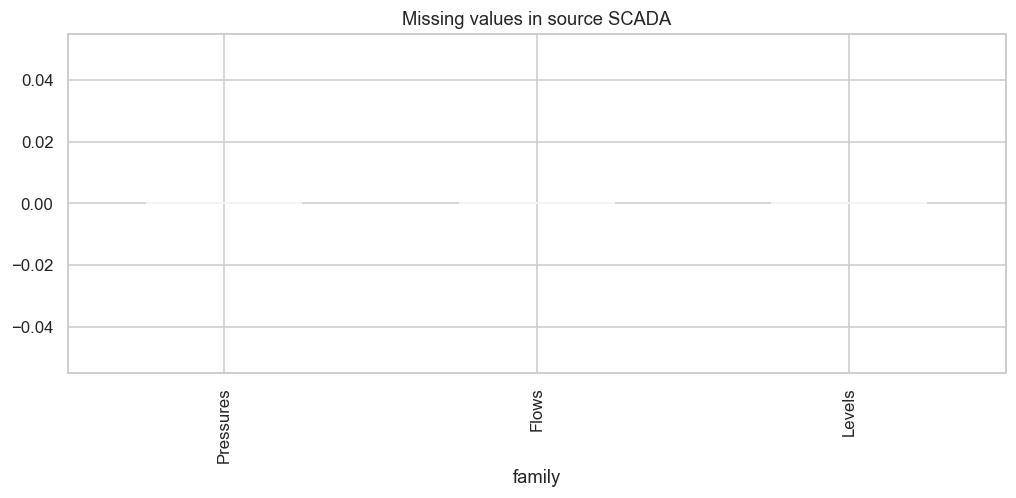

In [4]:
audit=[]
for name,d in measurements.items():
    audit.append({'family':name,'rows':len(d),'sensors':len(d.columns),'missing':int(d.isna().sum().sum()),'duplicate_times':int(d.index.duplicated().sum()),'cadence_minutes':d.index.to_series().diff().dt.total_seconds().median()/60})
    display(d.describe().T.head(8))
audit=pd.DataFrame(audit);display(audit);audit.to_csv(OUT/'data_audit.csv',index=False)
audit.plot.bar(x='family',y='missing',title='Missing values in source SCADA',legend=False);plt.show()

### Verify sensor placement

Every pressure/level sensor must exist as a node; every flow sensor must exist as a link.

In [5]:
link_ids={k for u,v,k in graph.edges(keys=True)}
assert set(measurements['Pressures']).issubset(graph.nodes)
assert set(measurements['Levels']).issubset(graph.nodes)
assert set(measurements['Flows']).issubset(link_ids)
print('All source sensor identities mapped to nominal EPANET topology.')
print('Connected components',nx.number_connected_components(graph))

All source sensor identities mapped to nominal EPANET topology.
Connected components 1


## 04. EDA: hydraulic patterns and topology

Analytical time-series EDA uses 2018 before September. Source-level coverage inspection is retained for both years; model selection never consults final 2019 targets.

### Pressure sensor distributions

Different elevations and positions generate different baseline pressures, so location IDs must be retained.

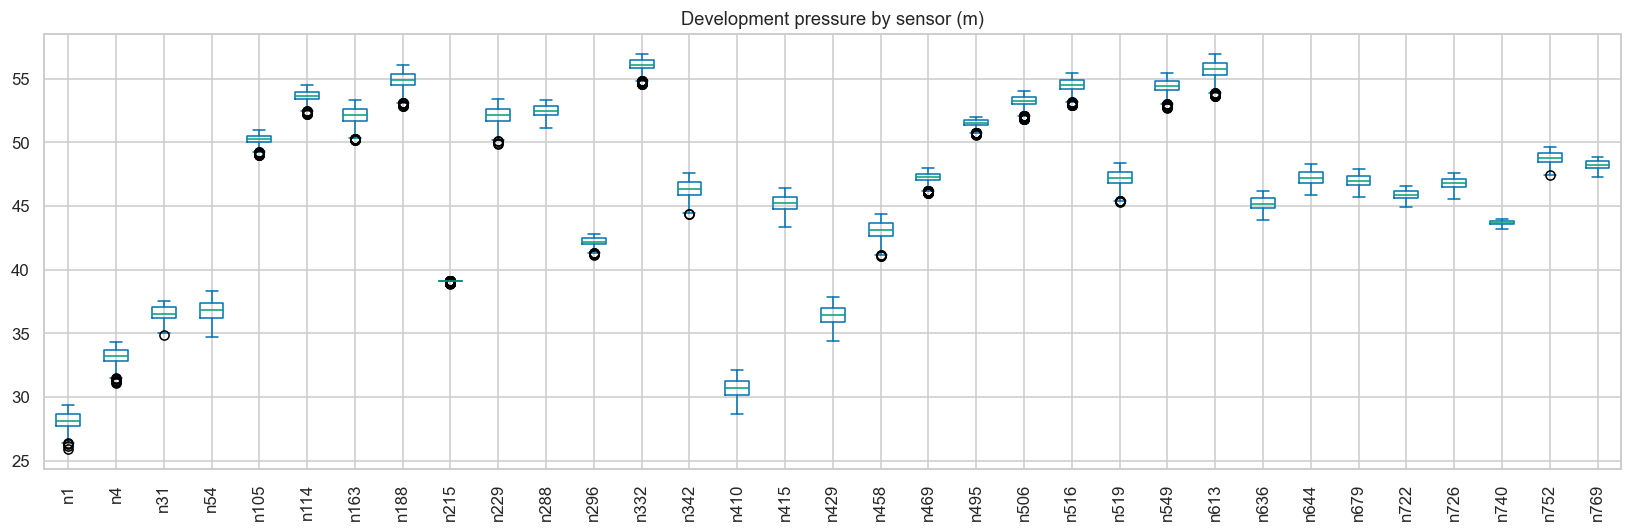

In [6]:
pressure=measurements['Pressures'].loc[:'2018-08-31'].iloc[::12]
pressure.plot.box(figsize=(15,5),rot=90,title='Development pressure by sensor (m)');plt.tight_layout();plt.show()

### Pressure and flow temporal traces

Five-minute readings are downsampled at exact hourly instants. No future interval average is assigned to an earlier observation.

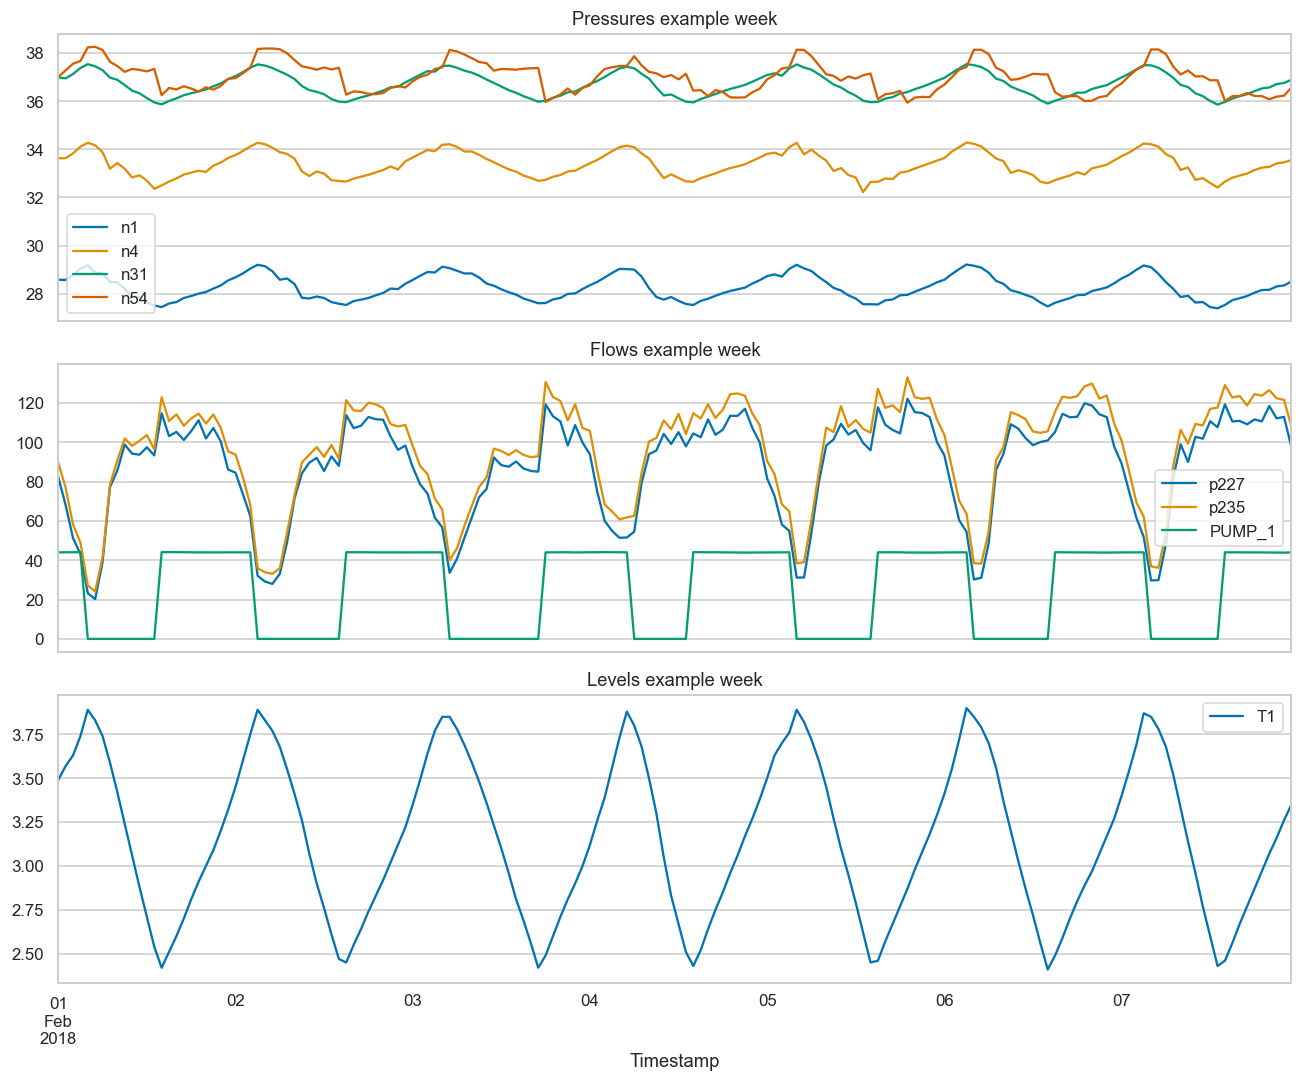

In [7]:
fig,ax=plt.subplots(3,1,figsize=(12,10),sharex=True)
for (family,d),a in zip(measurements.items(),ax):
    d.loc['2018-02-01':'2018-02-07'].iloc[::12,:min(4,len(d.columns))].plot(ax=a,title=family+' example week')
plt.tight_layout();plt.show()

### Diurnal demand-related patterns

Daily hydraulic cycles are consistent with demand variation. Nominal demand is a network input, not a measured customer-use label.

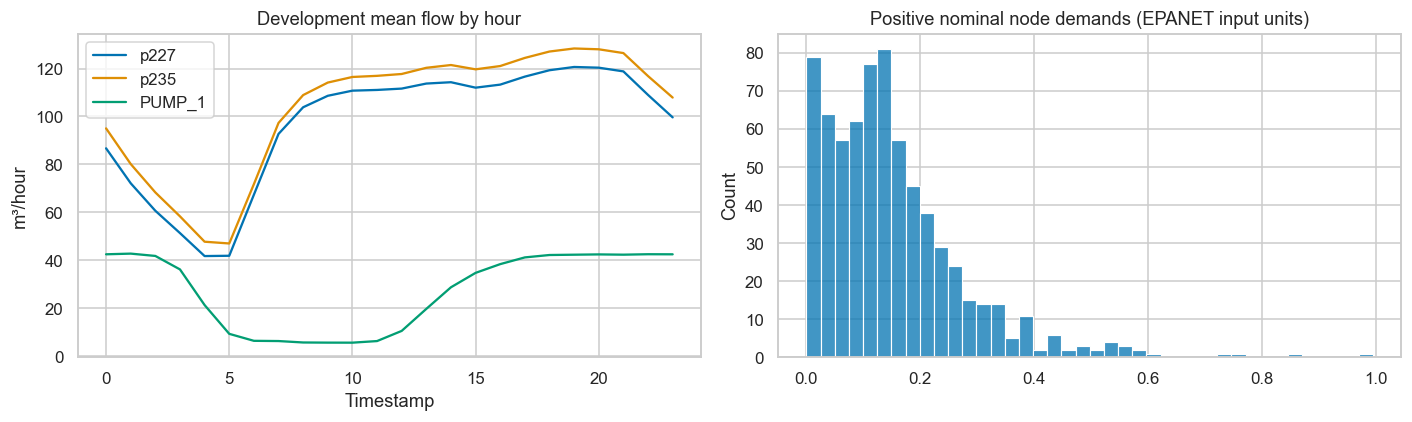

Nominal EPANET demand units are determined by its OPTIONS/UNITS; inspect below.
 Units              	CMH
 UNITS          	Meters


In [8]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
for col in measurements['Flows']:
    d=measurements['Flows'].loc[:'2018-08-31'];d.groupby(d.index.hour)[col].mean().plot(ax=ax[0],label=col)
ax[0].legend();ax[0].set(title='Development mean flow by hour',ylabel='m³/hour')
nominal=pd.Series(nx.get_node_attributes(graph,'base_demand'))
sns.histplot(nominal[nominal>0],bins=40,ax=ax[1]);ax[1].set_title('Positive nominal node demands (EPANET input units)')
plt.tight_layout();plt.show()
print('Nominal EPANET demand units are determined by its OPTIONS/UNITS; inspect below.')
lines=(DATA/'L-TOWN.inp').read_text().splitlines()
print('\n'.join(line for line in lines if 'Units' in line or 'UNITS' in line)[:500])

### Network map and sensor locations

Coordinates are benchmark plotting coordinates; edges are physical pipe adjacency, not civic dependency probabilities.

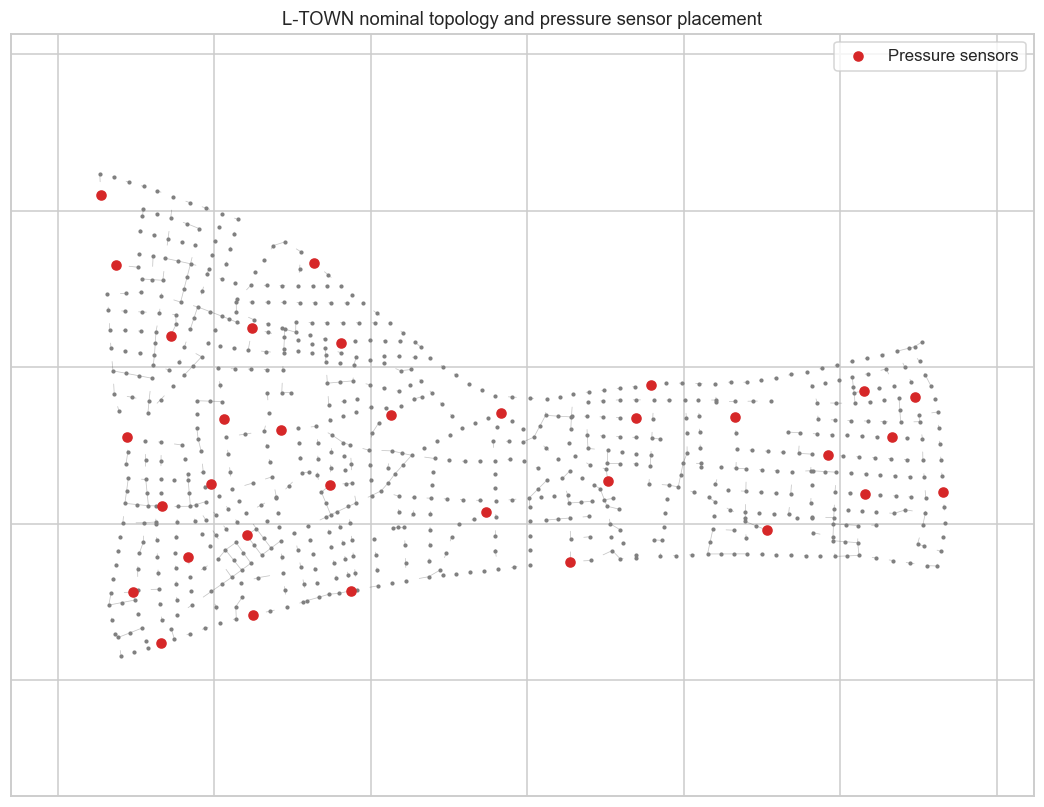

In [9]:
pos=nx.get_node_attributes(graph,'pos')
plt.figure(figsize=(12,9))
nx.draw_networkx_edges(graph,pos,alpha=.25,width=.5)
nx.draw_networkx_nodes(graph,pos,node_size=3,node_color='grey')
nx.draw_networkx_nodes(graph,pos,nodelist=list(measurements['Pressures'].columns),node_size=35,node_color='tab:red',label='Pressure sensors')
plt.legend();plt.title('L-TOWN nominal topology and pressure sensor placement');plt.axis('equal');plt.show()

### Sensor correlation and redundancy

Highly correlated pressures may reflect shared hydraulics. They are not independent fault confirmations.

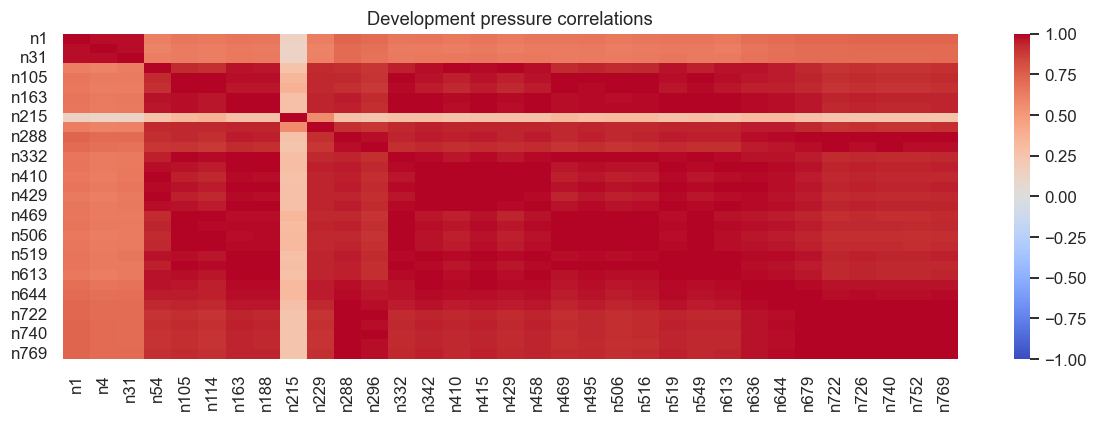

In [10]:
sns.heatmap(pressure.corr(),cmap='coolwarm',vmin=-1,vmax=1);plt.title('Development pressure correlations');plt.tight_layout();plt.show()

## 05. Leakage episodes and honest labels

Ground-truth leakage-flow columns are used only to identify the start of each positive contiguous episode. They are never features. The target is a preceding-24-hour onset window, not a generic active-leak flag. The public labels enable supervised benchmark experiments but do not validate real-world fault incidence.

### Create documented onset labels

The first positive leak-flow sample marks onset; the original five-minute resolution imposes detection-time granularity.

,event_id,pipe,onset,window_end
0,p257:0,p257,2018-01-09 00:30:00,2018-01-10 00:30:00
1,p461:0,p461,2018-01-23 23:55:00,2018-01-24 23:55:00
2,p232:0,p232,2018-01-31 03:45:00,2018-02-01 03:45:00
3,p427:0,p427,2018-02-16 04:15:00,2018-02-17 04:15:00
4,p673:0,p673,2018-03-05 15:45:00,2018-03-06 15:45:00
5,p628:0,p628,2018-05-02 18:50:00,2018-05-03 18:50:00
6,p538:0,p538,2018-05-18 08:35:00,2018-05-19 08:35:00
7,p866:0,p866,2018-06-01 09:05:00,2018-06-02 09:05:00
8,p31:0,p31,2018-06-29 01:35:00,2018-06-30 01:35:00
9,p654:0,p654,2018-07-07 09:10:00,2018-07-08 09:10:00


Recent-onset prevalence 0.045205479452054796


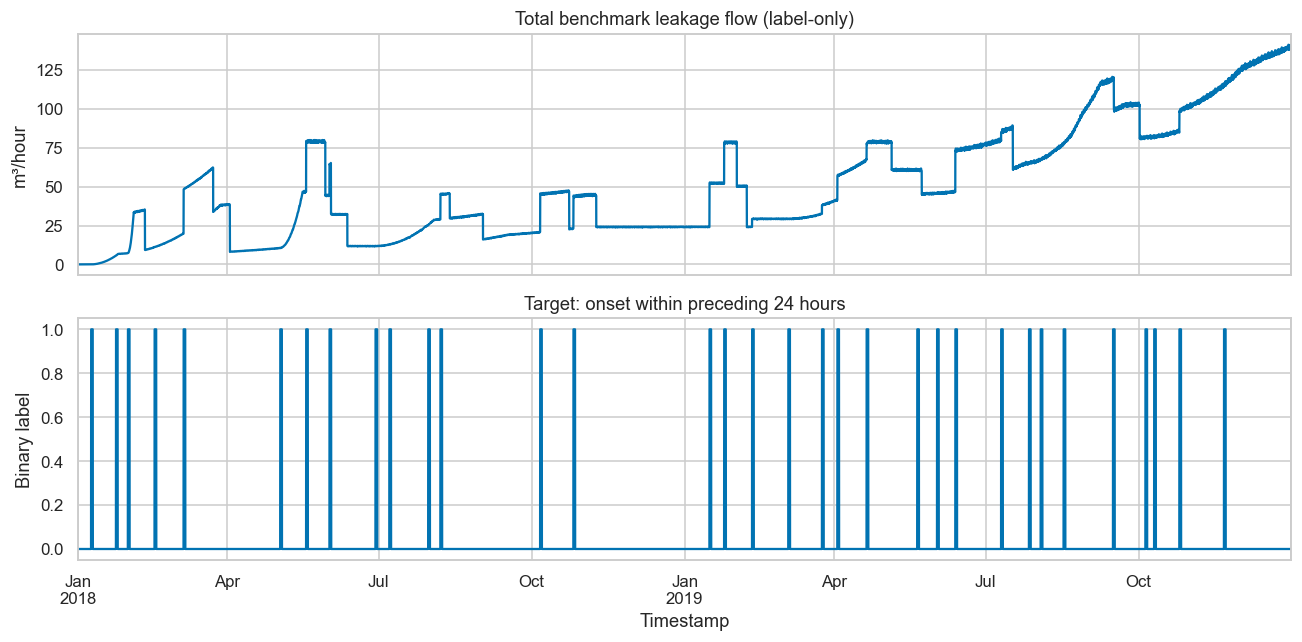

In [11]:
f=water_features(measurements)
y,events=onset_labels(leakages,f.index)
display(events);print('Recent-onset prevalence',y.mean())
events.to_csv(OUT/'label_events.csv',index=False)
fig,ax=plt.subplots(2,1,figsize=(12,6),sharex=True)
leakages.sum(axis=1).iloc[::12].plot(ax=ax[0],title='Total benchmark leakage flow (label-only)',ylabel='m³/hour')
y.plot(ax=ax[1],title='Target: onset within preceding 24 hours',ylabel='Binary label')
plt.tight_layout();plt.show()

### Inspect overlapping episodes

Simultaneous events reduce the interpretability of network-wide onset alerts. No individual pipe localization is claimed.

Maximum simultaneous active pipes 16
Hourly labels {0: 16728, 1: 792}


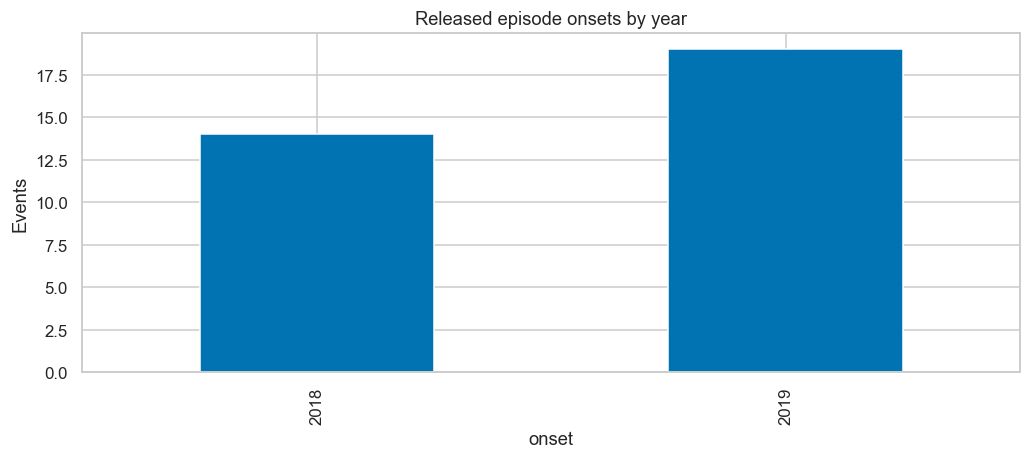

In [12]:
active=(leakages>1e-6).sum(axis=1)
print('Maximum simultaneous active pipes',int(active.max()))
print('Hourly labels',y.value_counts().to_dict())
events.groupby(events.onset.dt.year).size().plot.bar(title='Released episode onsets by year',ylabel='Events');plt.show()

## 06. Causal features and preprocessing

Features include each pressure/flow/level value at t, its one-hour difference, a trailing 24-hour mean, missingness and known clock phase. Label files and future observations are excluded. Numeric medians are fitted only on training folds. Logistic Regression is scaled; tree models are not. Hourly scoring reduces compute and bounds minimum resolution to roughly an hour; it is not five-minute competition performance.

### Feature schema and target exclusion

Serving uses exactly the same feature builder and ordered sensor contract.

In [13]:
feature_names=list(f.columns);numeric=feature_names;categorical=[]
assert not any('leak' in col.lower() for col in feature_names)
display(f.head(28).tail(6))
write_json(OUT/'feature_schema.json',{'features':feature_names,'units':UNITS,'sensor_ids':{k:list(v.columns) for k,v in measurements.items()}})

,pressure__n1,pressure__n1__delta1,pressure__n1__mean24,pressure__n1__missing,pressure__n4,pressure__n4__delta1,pressure__n4__mean24,pressure__n4__missing,pressure__n31,pressure__n31__delta1,...,flow__PUMP_1__delta1,flow__PUMP_1__mean24,flow__PUMP_1__missing,level__T1,level__T1__delta1,level__T1__mean24,level__T1__missing,hour_sin,hour_cos,weekday
Timestamp,,,,,,,,,,,,,,,,,,,,,
2018-01-01 22:00:00,28.49,0.07,28.493478,0,33.45,0.08,33.408696,0,36.73,0.08,...,-0.02,17.247826,0,3.17,0.12,3.157826,0,-0.500000,0.866025,0
2018-01-01 23:00:00,28.64,0.15,28.499583,0,33.60,0.15,33.416667,0,36.90,0.17,...,0.01,18.363750,0,3.30,0.13,3.163750,0,-0.258819,0.965926,0
2018-01-02 00:00:00,28.83,0.19,28.495833,0,33.77,0.17,33.412500,0,37.07,0.17,...,0.03,18.364583,0,3.45,0.15,3.161667,0,0.000000,1.000000,1
2018-01-02 01:00:00,29.03,0.20,28.491667,0,33.97,0.20,33.407917,0,37.24,0.17,...,0.02,18.365417,0,3.61,0.16,3.158750,0,0.258819,0.965926,1
2018-01-02 02:00:00,29.24,0.21,28.487917,0,34.19,0.22,33.404167,0,37.45,0.21,...,0.01,18.366667,0,3.79,0.18,3.155000,0,0.500000,0.866025,1
2018-01-02 03:00:00,29.35,0.11,28.495000,0,34.30,0.11,33.412083,0,37.55,0.10,...,-44.09,18.366667,0,3.89,0.10,3.157917,0,0.707107,0.707107,1


### Future perturbation test

Changing future pressure observations must leave earlier feature rows identical.

In [14]:
copy={k:v.copy() for k,v in measurements.items()}
cut=pd.Timestamp('2018-06-01');copy['Pressures'].loc[copy['Pressures'].index>cut]=9999
pd.testing.assert_frame_equal(f.loc[:cut],water_features(copy).loc[:cut])
print('PASS: causal water features')

PASS: causal water features


## 07. Time- and event-aware validation

Development: January–August 2018. Validation: September–December 2018. Final: 2019. Any 24-hour onset target episode crossing a boundary is excluded with a 24-hour context buffer. Expanding CV uses a 24-hour gap, preventing one onset window from appearing on both sides of a fold. Older persistent leakage remains possible in negative examples by target definition. These choices are frozen before final evaluation.

### Construct and audit splits

Both classes must exist in each fold; otherwise the study stops rather than reporting meaningless PR-AUC.

In [15]:
data=split_water(f,y,events)
train=data[data.period.eq('train')];val=data[data.period.eq('validation')];test=data[data.period.eq('test')]
Xtrain,ytrain=train[feature_names],train.target
Xval,yval=val[feature_names],val.target
Xtest,ytest=test[feature_names],test.target
folds=list(TimeSeriesSplit(n_splits=3,gap=24).split(Xtrain))
for tr,va in folds:
    assert Xtrain.index[tr].max()<Xtrain.index[va].min()-pd.Timedelta(hours=23)
    assert ytrain.iloc[tr].nunique()==2 and ytrain.iloc[va].nunique()==2
split_report=pd.DataFrame([{'split':s,'n':len(d),'positive':d.target.sum(),'start':str(d.index.min()),'end':str(d.index.max())} for s,d in [('train',train),('validation',val),('test',test)]])
display(split_report);split_report.to_csv(OUT/'splits.csv',index=False)

,split,n,positive,start,end
0,train,5808,288,2018-01-02 00:00:00,2018-08-31 23:00:00
1,validation,2928,48,2018-09-01 00:00:00,2018-12-31 23:00:00
2,test,8760,456,2019-01-01 00:00:00,2019-12-31 23:00:00


### Rule-based baseline

Pressure-change/flow-change robust deviations are learned from training data only. This rule is an interpretable comparison, not an official operating threshold.

In [16]:
rule=WaterRule().fit(Xtrain)
rule_val=rule.predict_proba(Xval)[:,1]
rule_threshold,rule_thresholds=choose_threshold(yval,rule_val)
print('Validation rule threshold',rule_threshold)

Validation rule threshold 0.06642712025148022


## 08. Model comparisons and tuning

Compare Logistic Regression, Random Forest and XGBoost against the prior and hydraulic-change rule. Train/validation/test roles are distinct. Tuning CV scores may be optimistic; final evaluation is independent.

### Declare model candidates

All learned transforms are refitted within CV. The prior baseline is eligible to win; class balance is not altered on evaluation data.

In [17]:
models={'Prior':pipeline(DummyClassifier(strategy='prior'),numeric,categorical),
        'Logistic':pipeline(LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED),numeric,categorical,True),
        'XGBoost':pipeline(XGBClassifier(n_estimators=140,max_depth=3,learning_rate=.06,subsample=.85,colsample_bytree=.85,eval_metric='logloss',tree_method='hist',n_jobs=2,random_state=SEED),numeric,categorical)}
models['Random Forest']=pipeline(RandomForestClassifier(n_estimators=100,max_depth=12,min_samples_leaf=5,class_weight='balanced',random_state=SEED,n_jobs=2),numeric,categorical)
print('Candidates',list(models))

Candidates ['Prior', 'Logistic', 'XGBoost', 'Random Forest']


### Cross-validated comparisons

Average precision (PR-AUC summary) is primary; fold dispersion is reported. Development scores are selection estimates, not independent final performance.

,AP,AP_std,Brier
model,,,
Logistic,0.047909,0.014080,0.330543
Prior,0.044077,0.021877,0.042707
XGBoost,0.037681,0.017008,0.051104
Random Forest,0.037319,0.018253,0.063519


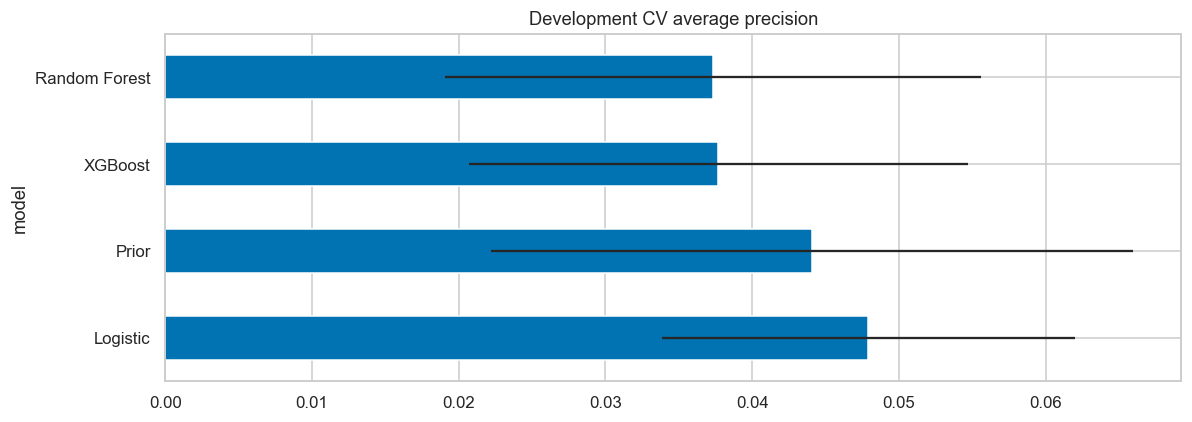

In [18]:
rows=[]
for name,model in models.items():
    scores=cross_validate(model,Xtrain,ytrain,cv=folds,scoring={'ap':'average_precision','brier':'neg_brier_score'},error_score='raise',n_jobs=1)
    for i in range(len(folds)):rows.append({'model':name,'fold':i,'AP':scores['test_ap'][i],'Brier':-scores['test_brier'][i]})
cv_results=pd.DataFrame(rows)
summary=cv_results.groupby('model').agg(AP=('AP','mean'),AP_std=('AP','std'),Brier=('Brier','mean')).sort_values('AP',ascending=False)
display(summary);cv_results.to_csv(OUT/'candidate_cv.csv',index=False)
summary.AP.plot.barh(xerr=summary.AP_std,title='Development CV average precision');plt.tight_layout();plt.show()

### Declared hyperparameter searches

Tune Logistic and XGBoost with four sampled settings each. The modest budget is explicit and repeatable; test labels never enter selection.

In [19]:
spaces={'Logistic':{'model__C':[.01,.1,1,10,100],'model__class_weight':[None,'balanced']},
        'XGBoost':{'model__n_estimators':[80,140,220],'model__max_depth':[2,3,5],'model__learning_rate':[.03,.08,.15],'model__min_child_weight':[1,5,10]}}
searches={};ranking=summary.AP.to_dict()
for name,space in spaces.items():
    search=RandomizedSearchCV(models[name],space,n_iter=4,scoring='average_precision',cv=folds,refit=True,n_jobs=1,random_state=SEED,error_score='raise')
    search.fit(Xtrain,ytrain);searches[name]=search;ranking[name+' tuned']=search.best_score_
    trials=pd.DataFrame(search.cv_results_);trials.to_csv(OUT/(name+'_tuning.csv'),index=False)
    display(trials.sort_values('rank_test_score')[['rank_test_score','mean_test_score','std_test_score','params']])
selected=max(ranking,key=ranking.get)
model=searches[selected.removesuffix(' tuned')].best_estimator_ if selected.endswith(' tuned') else clone(models[selected]).fit(Xtrain,ytrain)
print('Locked CV choice:',selected)

,rank_test_score,mean_test_score,std_test_score,params
3,1,0.104772,0.045347,"{'model__class_weight': None, 'model__C': 0.01}"
1,2,0.062263,0.022116,"{'model__class_weight': 'balanced', 'model__C'..."
0,3,0.052380,0.014951,"{'model__class_weight': None, 'model__C': 100}"
2,4,0.047909,0.011496,"{'model__class_weight': 'balanced', 'model__C'..."


,rank_test_score,mean_test_score,std_test_score,params
0,1,0.062386,0.020013,"{'model__n_estimators': 80, 'model__min_child_..."
3,2,0.060327,0.018679,"{'model__n_estimators': 140, 'model__min_child..."
2,3,0.060082,0.020142,"{'model__n_estimators': 140, 'model__min_child..."
1,4,0.046571,0.011706,"{'model__n_estimators': 80, 'model__min_child_..."


Locked CV choice: Logistic tuned


### Validation-only threshold repair

Search the observed validation score range, including scores below 0.05. Maximize validation F1 and retain the highest threshold on a tie. This research alert rule has no operational authority. The original coarse grid excluded useful low-score operating points; none of its cutoffs detected a validation positive.

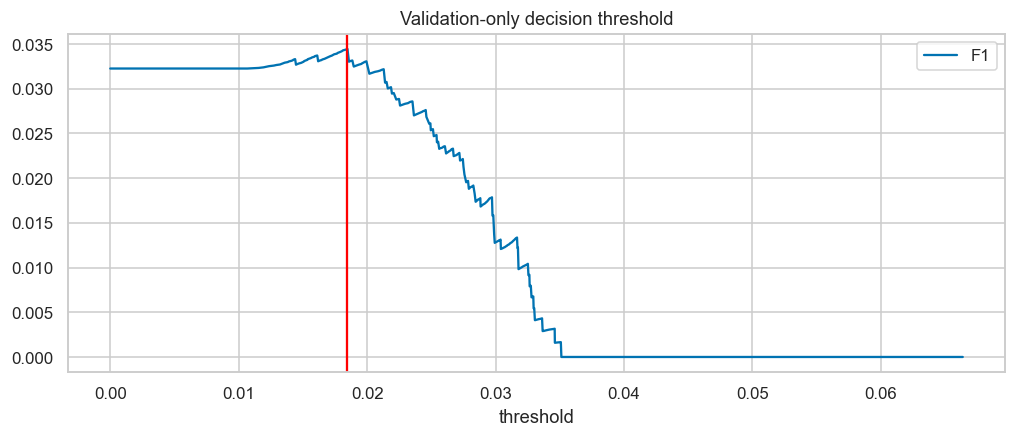

Locked threshold 0.01846993037125683


In [20]:
pval=model.predict_proba(Xval)[:,1]
threshold,threshold_table=choose_threshold(yval,pval)
threshold_table.to_csv(OUT/'threshold_validation.csv',index=False)
threshold_table.plot(x='threshold',y='F1',title='Validation-only decision threshold');plt.axvline(threshold,color='red');plt.show()
print('Locked threshold',threshold)

## 09. Final evaluation and detection delay

Metrics apply only to released benchmark onset-window labels. False-positive rate means outside the recent-onset target window; it does not mean absence of all active leakage. Delays are measured from each held-out episode onset to the first hourly alert in its 24-hour target window. Misses are retained separately rather than assigned zero delay.

### Locked final evaluation

No final-period outcome is used to pick the model or change its threshold.

precision                      0.062346
recall                         0.666667
F1                             0.114029
PR_AUC_average_precision       0.064881
ROC_AUC                        0.577279
Brier                          0.049972
false_positive_rate            0.550578
false_positives             4572.000000
false_negatives              152.000000
n                           8760.000000
prevalence                     0.052055
dtype: float64

              precision    recall  f1-score   support

           0       0.96      0.45      0.61      8304
           1       0.06      0.67      0.11       456

    accuracy                           0.46      8760
   macro avg       0.51      0.56      0.36      8760
weighted avg       0.91      0.46      0.59      8760



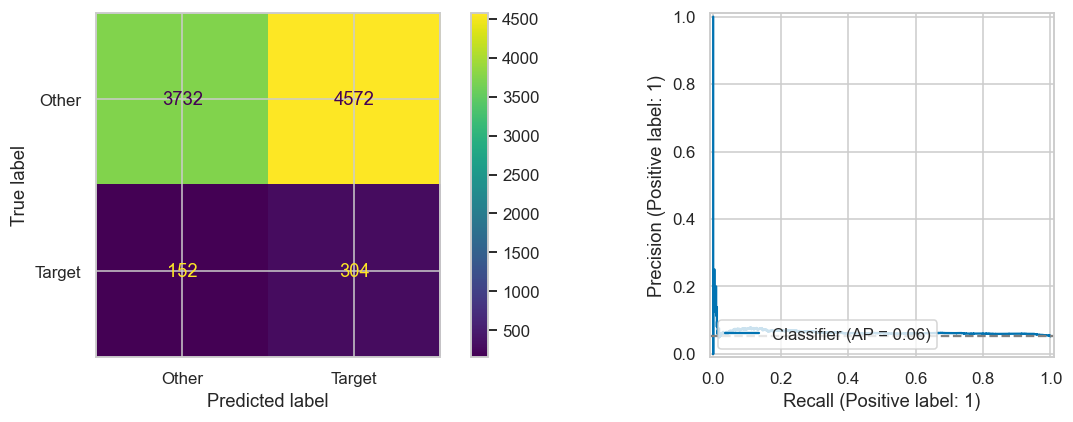

In [21]:
ptest=model.predict_proba(Xtest)[:,1]
metrics=binary_metrics(ytest,ptest,threshold)
display(pd.Series(metrics));print(classification_report(ytest,ptest>=threshold,zero_division=0))
write_json(OUT/'metrics.json',metrics)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ConfusionMatrixDisplay.from_predictions(ytest,ptest>=threshold,ax=ax[0],display_labels=['Other','Target'])
PrecisionRecallDisplay.from_predictions(ytest,ptest,ax=ax[1]);ax[1].axhline(np.mean(ytest),ls='--',color='grey')
plt.tight_layout();plt.show()

### Probability reliability and error distribution

Uncalibrated scores may be poorly calibrated under domain shift; a probability-looking number is not proof of real-world validity.

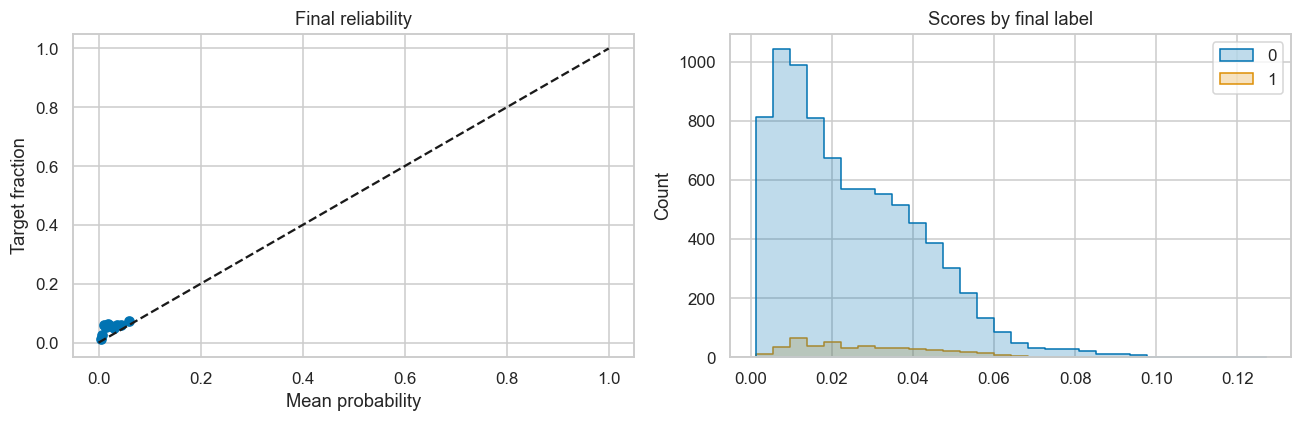

In [22]:
fraction,mean=calibration_curve(ytest,ptest,n_bins=10,strategy='quantile')
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(mean,fraction,marker='o');ax[0].plot([0,1],[0,1],'k--');ax[0].set(title='Final reliability',xlabel='Mean probability',ylabel='Target fraction')
sns.histplot(x=ptest,hue=np.asarray(ytest),bins=30,element='step',ax=ax[1]);ax[1].set_title('Scores by final label')
plt.tight_layout();plt.show()

### Rule comparison and hourly trace

The learned winner remains the CV choice regardless of final comparison results.

,model,precision,recall,F1,PR_AUC_average_precision,ROC_AUC,Brier,false_positive_rate,false_positives,false_negatives,n,prevalence
0,Logistic tuned,0.062346,0.666667,0.114029,0.064881,0.577279,0.049972,0.550578,4572,152,8760,0.052055
1,Hydraulic change rule,0.053096,0.804825,0.099620,0.050821,0.497434,0.106171,0.788174,6545,89,8760,0.052055


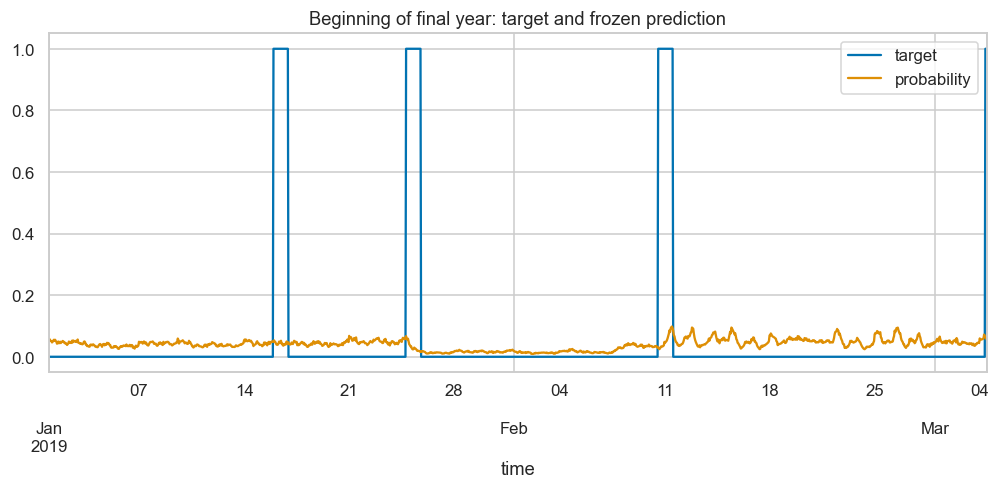

In [23]:
rule_test=rule.predict_proba(Xtest)[:,1]
comparison=pd.DataFrame([{'model':selected,**metrics},{'model':'Hydraulic change rule',**binary_metrics(ytest,rule_test,rule_threshold)}])
display(comparison);comparison.to_csv(OUT/'final_comparison.csv',index=False)
results=pd.DataFrame({'time':Xtest.index,'target':ytest.to_numpy(),'probability':ptest,'alert':ptest>=threshold})
results.to_csv(OUT/'test_predictions.csv',index=False)
results.set_index('time')[['target','probability']].iloc[:1500].plot(title='Beginning of final year: target and frozen prediction');plt.show()

### Event recovery and onset-to-alert delay

Report detected fraction plus delay among detected episodes; a small conditional delay can coexist with many misses.

In [24]:
delays=[]
for r in events.itertuples():
    if r.onset.year!=2019:continue
    window=results[(results.time>=r.onset)&(results.time<r.window_end)]
    if len(window)<20:continue
    alerts=window[window.alert]
    delays.append({'event_id':r.event_id,'pipe':r.pipe,'onset':str(r.onset),'detected':len(alerts)>0,
                   'delay_hours':(alerts.time.iloc[0]-r.onset).total_seconds()/3600 if len(alerts) else np.nan})
delays=pd.DataFrame(delays);display(delays);delays.to_csv(OUT/'event_detection_delay.csv',index=False)
print('Event detection fraction',delays.detected.mean(),'Median detected delay hours',delays.delay_hours.median())
false=results[results.target.eq(0)].copy()
print('False alert hours outside onset target windows:',int(false.alert.sum()))

,event_id,pipe,onset,detected,delay_hours
0,p523:0,p523,2019-01-15 23:00:00,True,0.000000
1,p827:0,p827,2019-01-24 18:30:00,True,0.500000
2,p280:0,p280,2019-02-10 13:05:00,True,0.916667
3,p653:0,p653,2019-03-04 08:40:00,True,0.333333
4,p710:0,p710,2019-03-24 14:15:00,True,0.750000
5,p514:0,p514,2019-04-02 20:40:00,True,0.333333
6,p331:0,p331,2019-04-20 10:10:00,True,0.833333
7,p193:0,p193,2019-05-20 21:55:00,True,0.083333
8,p277:0,p277,2019-06-01 19:40:00,True,0.333333
9,p142:0,p142,2019-06-12 19:55:00,True,0.083333


Event detection fraction 0.8947368421052632 Median detected delay hours 0.5
False alert hours outside onset target windows: 4572


## 10. Error analysis and robustness

Inspect time/season dependence and failures. Do not tune on these final outcomes. The absence of field labels, receipt times and verified municipal mapping prevents operational use.

### Monthly error slices

Seasonality and changing leak scenarios may differ between 2018 and 2019.

,month,precision,recall,F1,PR_AUC_average_precision,ROC_AUC,Brier,false_positive_rate,false_positives,false_negatives,n,prevalence
0,1,0.071770,0.937500,0.133333,0.083657,0.517421,0.061143,0.836207,582,3,744,0.064516
1,2,0.045028,1.000000,0.086176,0.177797,0.631559,0.033966,0.785494,509,0,672,0.035714
2,3,0.064516,1.000000,0.121212,0.074145,0.587494,0.060698,1.000000,696,0,744,0.064516
3,4,0.069164,1.000000,0.129380,0.077816,0.559772,0.063026,0.961310,646,0,720,0.066667
4,5,0.034532,1.000000,0.066759,0.147346,0.721296,0.030677,0.931944,671,0,744,0.032258
5,6,0.061224,0.625000,0.111524,0.067240,0.475136,0.064184,0.684524,460,18,720,0.066667
6,7,0.098870,0.729167,0.174129,0.096881,0.613176,0.062033,0.458333,319,13,744,0.064516
7,8,0.078261,0.750000,0.141732,0.069772,0.550886,0.062073,0.609195,424,12,744,0.064516
8,9,0.046875,0.250000,0.078947,0.044031,0.605484,0.032602,0.175287,122,18,720,0.033333
9,10,0.053333,0.111111,0.072072,0.086341,0.483424,0.094536,0.211310,142,64,744,0.096774


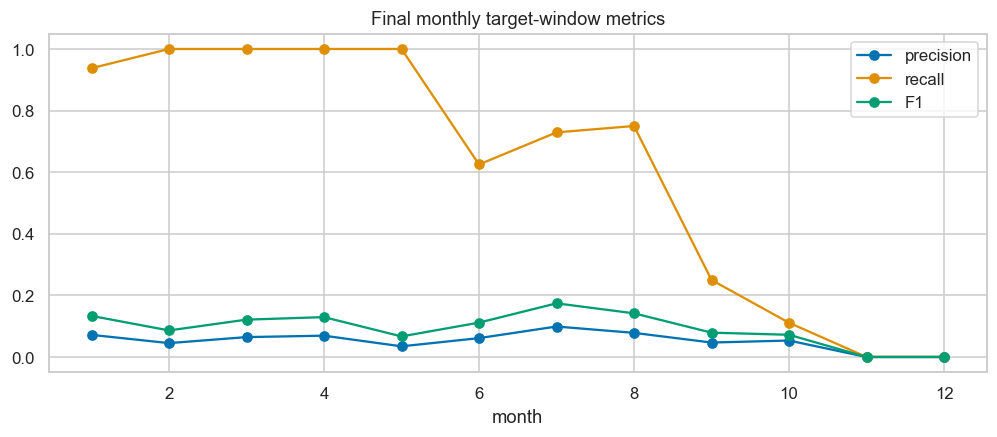

In [25]:
slices=[]
for month,indices in results.groupby(results.time.dt.month).groups.items():
    g=results.loc[indices];slices.append({'month':month,**binary_metrics(g.target,g.probability,threshold)})
slices=pd.DataFrame(slices);display(slices)
slices.plot(x='month',y=['precision','recall','F1'],marker='o',title='Final monthly target-window metrics');plt.show()

### Missing-sensor sensitivity

A controlled 20% current-sensor outage is explicitly artificial and must cause serving abstention later.

In [26]:
probe={k:v.tail(24*12+1).copy() for k,v in measurements.items()}
last_hour=probe['Pressures'].index[probe['Pressures'].index.minute==0][-1]
probe['Pressures'].loc[last_hour,probe['Pressures'].columns[:10]]=np.nan
print('Injected missing pressure sensor count',probe['Pressures'].loc[last_hour].isna().sum())

Injected missing pressure sensor count 10


## 11. Interpretability

Feature importance and SHAP describe statistical associations in the benchmark. Pressure patterns are correlated; explanations do not identify the true leaking pipe or establish causation.

### Permutation importance of the chosen model

Feature associations are not causal effects. Correlated variables can divide importance; no feature reselection occurs after final evaluation.

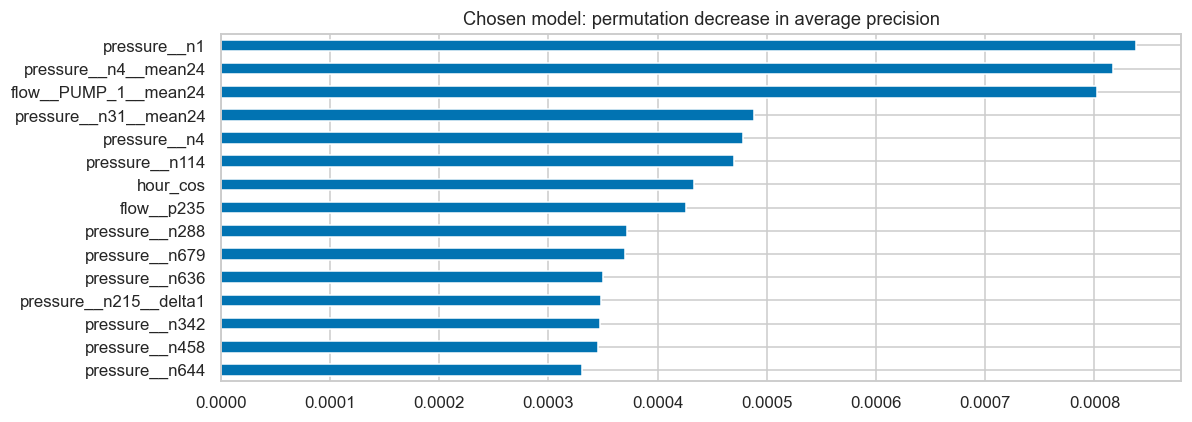

In [27]:
sample=Xval.sample(min(160,len(Xval)),random_state=SEED)
y_sample=yval.loc[sample.index]
pi=permutation_importance(model,sample,y_sample,scoring='average_precision',n_repeats=3,random_state=SEED,n_jobs=1)
importance=pd.Series(pi.importances_mean,index=feature_names).sort_values()
importance.tail(15).plot.barh(title='Chosen model: permutation decrease in average precision');plt.tight_layout();plt.show()
importance.to_csv(OUT/'permutation_importance.csv')

### SHAP global and individual explanation

SHAP explains the fitted raw classifier output. If a prior baseline wins, an auxiliary XGBoost explanation is explicitly identified.

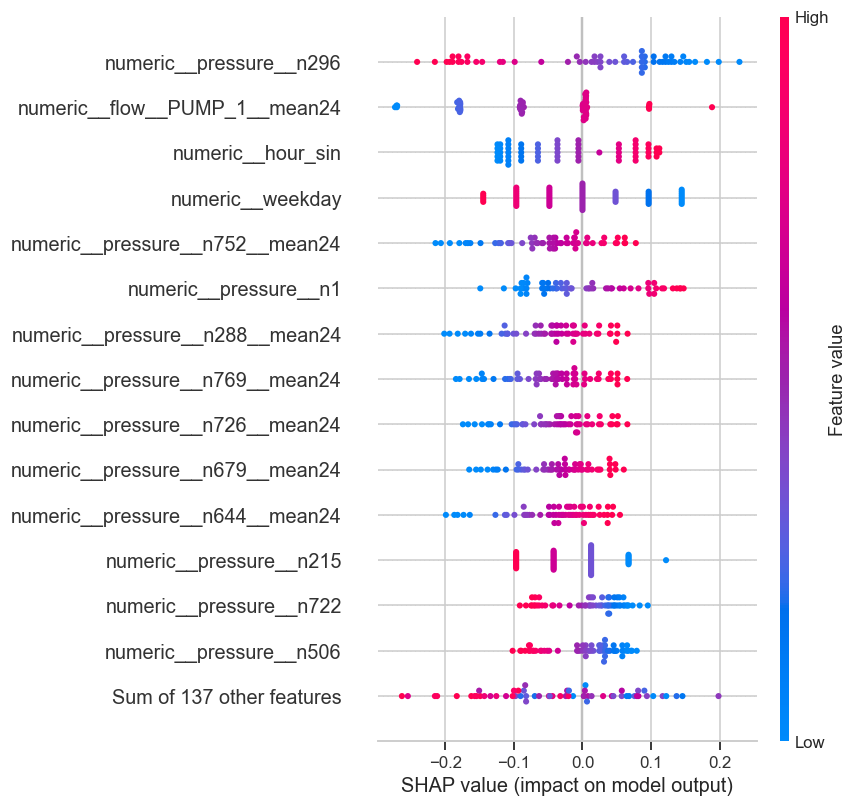

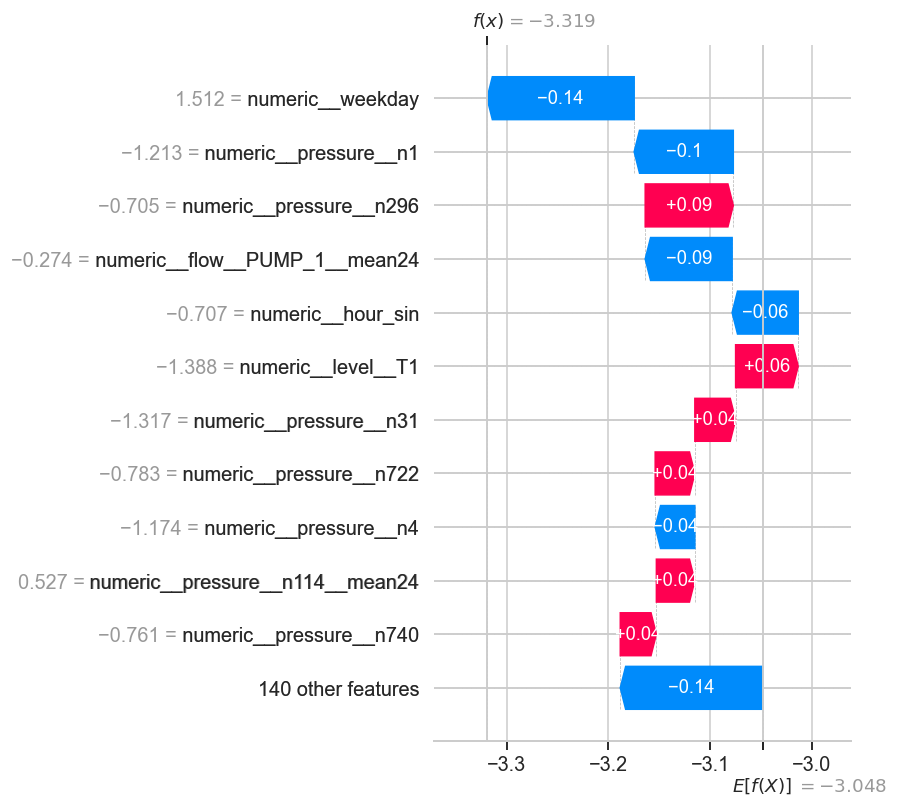

In [28]:
import shap
explained=model
if isinstance(model.named_steps['model'],DummyClassifier):
    explained=searches['XGBoost'].best_estimator_;print('Auxiliary XGBoost, not selected prior baseline')
transformed=explained.named_steps['preprocess'].transform(sample.iloc[:60])
classifier=explained.named_steps['model']
if isinstance(classifier,LogisticRegression):
    background=explained.named_steps['preprocess'].transform(Xtrain.sample(min(100,len(Xtrain)),random_state=SEED))
    ex=shap.LinearExplainer(classifier,background)(transformed)
else:
    ex=shap.TreeExplainer(classifier)(transformed)
    if ex.values.ndim==3:ex=ex[:,:,1]
ex.feature_names=list(explained.named_steps['preprocess'].get_feature_names_out())
shap.plots.beeswarm(ex,max_display=15,show=False);plt.tight_layout();plt.show()
shap.plots.waterfall(ex[0],max_display=12,show=False);plt.tight_layout();plt.show()

## 12. Export and validated inference

Export the fitted model, preprocessing, threshold, units, ordered sensor IDs, feature recipe and source manifest. Unsupported network/unit contracts abstain; wrong sensor identity or timestamp alignment is rejected. Missing-current coverage above 10% abstains. No prediction can dispatch resources.

### Save model, metadata and examples

All serialized objects are actually fitted and importable outside Jupyter.

In [29]:
metadata={'component':'water_recent_leak_onset','version':'1.1.0','selected_model':selected,'threshold':threshold,'train_end':str(Xtrain.index.max()),
          'target':'new benchmark leak began in preceding 24h','synthetic_benchmark':True,'source_doi':'10.5281/zenodo.4017659','license':'CC BY 4.0',
          'units':UNITS,'metrics':metrics,'dispatch_allowed':False,'validation':'retrospective hourly benchmark; not official challenge evaluation',
          'versions':{p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','xgboost','networkx']}}
bundle=WaterBundle(model,feature_names,{k:list(d.columns) for k,d in measurements.items()},threshold,metadata)
joblib.dump(bundle,OUT/'pipeline.joblib');write_json(OUT/'metadata.json',metadata)
loaded=joblib.load(OUT/'pipeline.joblib')
example={k:d.tail(24*12+1) for k,d in measurements.items()}
output=loaded.predict(example,UNITS,detected_at='2026-10-25T00:00:00Z')
assert output==bundle.predict(example,UNITS,detected_at='2026-10-25T00:00:00Z')
assert loaded.predict(probe,UNITS)['probability'] is None
assert loaded.predict(example,{'pressure':'psi'})['probability'] is None
print(json.dumps(output,indent=2));write_json(OUT/'example_prediction.json',output)

{
  "component": "water_recent_leak_onset",
  "version": "1.1.0",
  "network_id": "L-TOWN",
  "research_only": true,
  "synthetic_benchmark": true,
  "confirmed_failure": false,
  "dispatch_allowed": false,
  "provenance": "BattLeDIM simulated benchmark; not Delhi incidents",
  "status": "supported_research",
  "operational_supported": false,
  "target": "a benchmark leak began within the preceding 24 hours",
  "probability": 0.005342764673435297,
  "alert": false,
  "warnings": [
    "Benchmark distribution only; recent-onset detection is not leak localization or proof of a fault.",
    "Source clock/receipt latency is unspecified; no operational freshness claim."
  ],
  "threshold": 0.01846993037125683,
  "observation_time": "2019-12-31 23:00:00",
  "detection_time": "2026-10-25T00:00:00+00:00",
  "units": {
    "pressure": "m",
    "flow": "m3/h",
    "level": "m"
  },
  "input_freshness": "unknown: source timezone unspecified",
  "missing_fraction": 0.0
}


## 13. CivicFlux integration, findings and limitations

The shared `src/civicflux/` architecture is reused. No CivicFlux FastAPI risk/approval schema was found in the workspace; the output is a versioned pure inference contract, not a claim of live API integration. The nominal water topology remains separate from synthetic cross-sector dependencies. Anomaly/fault evidence requires corroboration and verified sensor-to-asset mapping.

Important limitations: retrospective simulated benchmark, hourly rather than five-minute scoring, recent-onset target rather than universal active-fault detection, no localization, limited independent events, unknown operational latency and timezone, and no calibrated field effectiveness. Source receipt-time and actual municipal sensor/fault data are the next dependencies.

### Actual final findings

All findings below are computed by this run; failures remain visible.

In [30]:
print('CV-selected model',selected)
print('Final benchmark metrics',json.dumps(metrics,indent=2))
print('Detected onset episodes',int(delays.detected.sum()),'of',len(delays))
print('Network/sensor map',graph.number_of_nodes(),graph.number_of_edges(),{k:len(v.columns) for k,v in measurements.items()})

CV-selected model Logistic tuned
Final benchmark metrics {
  "precision": 0.062346185397867106,
  "recall": 0.6666666666666666,
  "F1": 0.1140285071267817,
  "PR_AUC_average_precision": 0.06488099358540966,
  "ROC_AUC": 0.5772785996180239,
  "Brier": 0.04997190703784851,
  "false_positive_rate": 0.5505780346820809,
  "false_positives": 4572,
  "false_negatives": 152,
  "n": 8760,
  "prevalence": 0.052054794520547946
}
Detected onset episodes 17 of 19
Network/sensor map 785 909 {'Pressures': 33, 'Flows': 3, 'Levels': 1}


## Targeted review — operating points, events, false alarms and shift

The original 0.05–0.95 grid yielded zero validation F1 at every setting, then chose 0.95 by its tie rule. This is an inadequate search grid, not evidence that 0.95 is meaningful. We retain the same trained candidates and now examine actual validation-score operating points. Only validation labels determine thresholds; test labels diagnose the frozen policy.

Event recovery uses complete preceding-24-hour onset windows. One network-wide alert may overlap multiple leaks, so this is not localization or independent incident confirmation. False-alarm episodes are contiguous alert runs with no positive target hour; false-alert hours are also reported because a long false run can hide behind a small episode count.

,model,threshold,selection_period,precision,recall,F1,PR_AUC_average_precision,ROC_AUC,Brier,false_positive_rate,false_positives,false_negatives,n,prevalence
0,Selected ML,0.018470,2018 validation,0.062346,0.666667,0.114029,0.064881,0.577279,0.049972,0.550578,4572,152,8760,0.052055
1,Train prior,0.049587,2018 validation,0.052055,1.000000,0.098958,0.052055,0.500000,0.049351,1.000000,8304,0,8760,0.052055
2,Hydraulic changes,0.066427,2018 validation,0.053096,0.804825,0.099620,0.050821,0.497434,0.106171,0.788174,6545,89,8760,0.052055
3,Seasonal directional residual,0.921323,2018 validation,0.049180,0.526316,0.089955,0.049231,0.485344,0.711617,0.558767,4640,216,8760,0.052055


,model,events,recovered_events,event_recall,median_delay_hours_detected_only,alert_hours,false_alert_hours,false_alert_hours_per_negative_day,alert_episodes,false_alarm_episodes,false_alarm_episodes_per_30_days
0,Selected ML,19,17,0.894737,0.500000,4876,4572,13.213873,202,180,14.794521
1,Train prior,19,19,1.000000,0.333333,8760,8304,24.000000,1,0,0.000000
2,Hydraulic changes,19,19,1.000000,0.583333,6912,6545,18.916185,1183,1111,91.315068
3,Seasonal directional residual,19,15,0.789474,0.750000,4880,4640,13.410405,372,345,28.356164


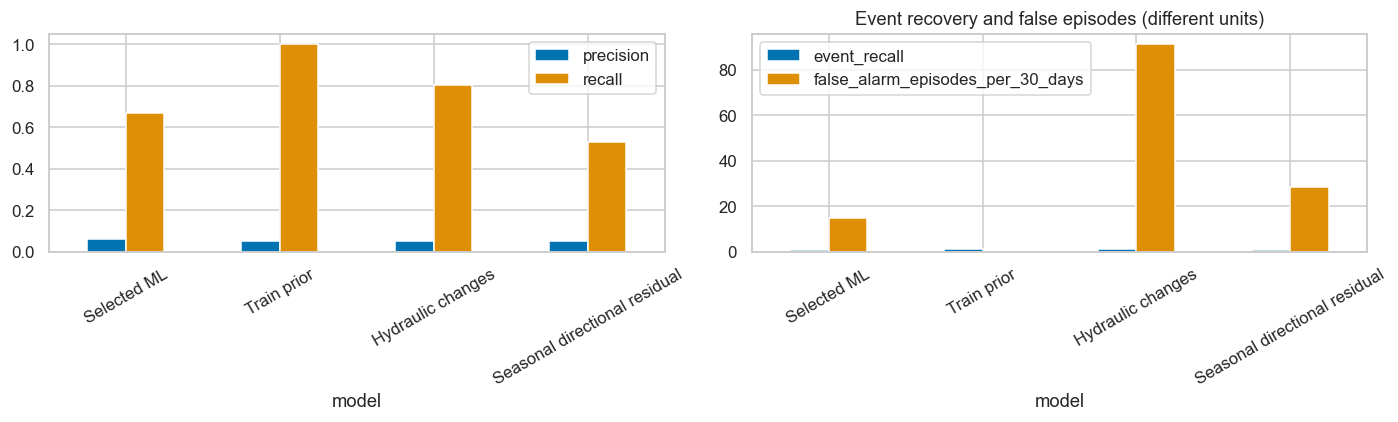

In [31]:
from src.civicflux.review import SeasonalHydraulicRule,event_metrics,select_score_threshold
from src.civicflux.contracts import standardize
prior=float(ytrain.mean())
seasonal=SeasonalHydraulicRule().fit(Xtrain)
score_sets={'Selected ML':(pval,ptest),'Train prior':(np.repeat(prior,len(yval)),np.repeat(prior,len(ytest))),
 'Hydraulic changes':(rule.predict_proba(Xval)[:,1],rule.predict_proba(Xtest)[:,1]),
 'Seasonal directional residual':(seasonal.predict_proba(Xval)[:,1],seasonal.predict_proba(Xtest)[:,1])}
review_rows=[];event_rows=[];details=[]
review_predictions=pd.DataFrame({'time':Xtest.index,'target':ytest.to_numpy()})
for name,(validation_scores,test_scores) in score_sets.items():
    t,curve=select_score_threshold(yval,validation_scores)
    curve.to_csv(OUT/(name.replace(' ','_')+'_validation_thresholds.csv'),index=False)
    review_rows.append({'model':name,'threshold':t,'selection_period':'2018 validation',**binary_metrics(ytest,test_scores,t)})
    em,ed=event_metrics(Xtest.index,ytest,test_scores,t,events);event_rows.append({'model':name,**em});ed['model']=name;details.append(ed)
    review_predictions[name]=test_scores
baseline_review=pd.DataFrame(review_rows);event_review=pd.DataFrame(event_rows)
display(baseline_review);display(event_review)
baseline_review.to_csv(OUT/'baseline_comparison.csv',index=False);event_review.to_csv(OUT/'event_comparison.csv',index=False)
pd.concat(details).to_csv(OUT/'event_review_details.csv',index=False)
review_predictions.to_csv(OUT/'review_predictions.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(13,4))
baseline_review.plot.bar(x='model',y=['precision','recall'],ax=ax[0],rot=30)
event_review.plot.bar(x='model',y=['event_recall','false_alarm_episodes_per_30_days'],ax=ax[1],rot=30)
ax[1].set_title('Event recovery and false episodes (different units)');plt.tight_layout();plt.show()

### Temporal shift and uncertainty

Feature reference scales use training data only. The table reports median shifts in units of training standard deviation, not a causal explanation of failures. Score quantiles show whether thresholds extrapolate across periods. There are only two validation onsets, making threshold selection highly uncertain. The 2019 results were already inspected in the earlier study: this requested repair uses validation only, but cannot restore an untouched test set; a new future period is required for prospective confirmation. Retesting choices on 2019 would invalidate its role as the final evaluation.

,feature,validation_median_shift,test_median_shift,abs_test_shift
10,pressure__n288,-0.364255,-1.264181,1.264181
31,pressure__n752,-0.357869,-1.252542,1.252542
26,pressure__n644,-0.294449,-1.251407,1.251407
32,pressure__n769,-0.365756,-1.249665,1.249665
29,pressure__n726,-0.359285,-1.240113,1.240113
27,pressure__n679,-0.329450,-1.207982,1.207982
14,pressure__n410,-0.164724,-1.187387,1.187387
28,pressure__n722,-0.342929,-1.171674,1.171674
11,pressure__n296,-0.288485,-1.121885,1.121885
30,pressure__n740,-0.348078,-1.102247,1.102247


,training,validation,2019 test
0.00,0.011618,0.010671,0.001244
0.10,0.027949,0.018122,0.005618
0.50,0.045875,0.032688,0.021227
0.90,0.068368,0.043993,0.048707
0.99,0.151152,0.053857,0.076682
1.00,0.276653,0.066382,0.127044


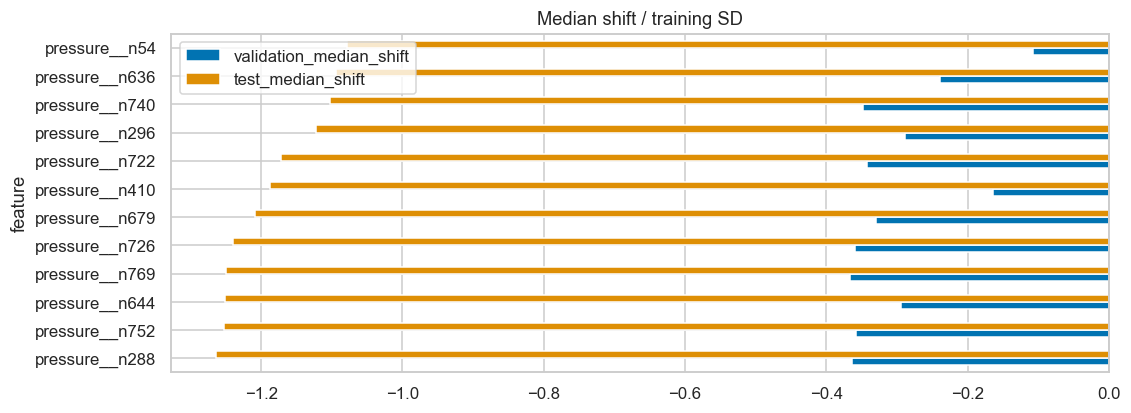

Original test metrics: {'precision': 0.0, 'recall': 0.0, 'F1': 0.0, 'PR_AUC_average_precision': 0.06488099358540966, 'ROC_AUC': 0.5772785996180239, 'Brier': 0.04997190703784851, 'false_positive_rate': 0.0, 'false_positives': 0, 'false_negatives': 456, 'n': 8760, 'prevalence': 0.052054794520547946}
Repaired validation-only threshold: 0.01846993037125683 new metrics: {'precision': 0.062346185397867106, 'recall': 0.6666666666666666, 'F1': 0.1140285071267817, 'PR_AUC_average_precision': 0.06488099358540966, 'ROC_AUC': 0.5772785996180239, 'Brier': 0.04997190703784851, 'false_positive_rate': 0.5505780346820809, 'false_positives': 4572, 'false_negatives': 152, 'n': 8760, 'prevalence': 0.052054794520547946}
Operational status: ABSTAIN. Benchmark onset scores do not establish municipal fault validity.


In [32]:
current=[c for c in feature_names if c.count('__')==1 and c.startswith(('pressure__','flow__','level__'))]
scale=Xtrain[current].std().clip(lower=.01)
shift=pd.DataFrame({'feature':current,'validation_median_shift':((Xval[current].median()-Xtrain[current].median())/scale).values,
 'test_median_shift':((Xtest[current].median()-Xtrain[current].median())/scale).values})
shift['abs_test_shift']=shift.test_median_shift.abs();display(shift.nlargest(12,'abs_test_shift'))
shift.to_csv(OUT/'temporal_distribution_shift.csv',index=False)
score_distribution=pd.DataFrame({name:pd.Series(scores).quantile([0,.1,.5,.9,.99,1]) for name,scores in
 [('training',model.predict_proba(Xtrain)[:,1]),('validation',pval),('2019 test',ptest)]})
display(score_distribution);score_distribution.to_csv(OUT/'score_distribution_by_period.csv')
shift.nlargest(12,'abs_test_shift').plot.barh(x='feature',y=['validation_median_shift','test_median_shift'],title='Median shift / training SD');plt.show()
print('Original test metrics:',json.loads((ROOT/'artifacts/water_network/v1.0.0/metrics.json').read_text()))
print('Repaired validation-only threshold:',threshold,'new metrics:',metrics)
print('Operational status: ABSTAIN. Benchmark onset scores do not establish municipal fault validity.')
metadata.update(version='1.1.0',operational_supported=False,operational_policy='abstain',validation_event_count=2)
bundle.metadata=metadata;joblib.dump(bundle,OUT/'pipeline.joblib');write_json(OUT/'metadata.json',metadata)
standardize('water_network',OUT,kind='supervised benchmark classifier',scope='L-TOWN simulated network only',units=UNITS,
 horizon='recent onset in preceding 24 hours',provenance='BattLeDIM CC BY 4.0 simulated SCADA',
 supported_inputs={'sensor_ids':bundle.sensors,'source_timezone':'unspecified naive','context':'24 hours five-minute history'},validation='weak temporal benchmark; operational abstention')
write_json(OUT/'example_prediction.json',bundle.predict(example,UNITS,detected_at='2026-10-25T00:00:00Z'))
assert bundle.predict(example,UNITS,purpose='operational')['probability'] is None